In [1]:
"""
Diachronic Projections for Passio/Pathos
ERC Proposal Case Study: Visualizing Sense Lineages
"""

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score
import umap
import tempun
from pathlib import Path

# Import our helpers
from projections_helpers import REDUCTIONS, get_2d, evaluate_projection_2d, create_label_palette
from lda_projections import LDAProjection, compute_lda_projection, evaluate_lda_vs_unsupervised

2026-10-09 17:56:17.107398: I tensorflow/core/util/port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
2026-10-09 17:56:17.141585: I tensorflow/core/platform/cpu_feature_guard.cc:210] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX512F AVX512_VNNI AVX512_BF16 AVX512_FP16 AVX_VNNI AMX_TILE AMX_INT8 AMX_BF16 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.


In [2]:
# Load classified datasets
passio_df = (pd.read_parquet("../data/large_files/passio_sample2000_classified.parquet"))
pathos_df = pd.read_parquet("../data/large_files/pathos_sample2000_classified.parquet")

print(f"Passio: {len(passio_df)} instances")
print(f"Pathos: {len(pathos_df)} instances")

Passio: 1000 instances
Pathos: 1000 instances


In [3]:

# Add temporal data
def get_random_date(row):
    random_date = tempun.model_date(row["not_before"], row["not_after"])
    if isinstance(random_date, (list, tuple)):
        random_date = random_date[0]
    return random_date

passio_df["random_date"] = passio_df.apply(get_random_date, axis=1)
pathos_df["random_date"] = pathos_df.apply(get_random_date, axis=1)

In [4]:
passio_df = passio_df[passio_df["random_date"].notna()]
pathos_df = pathos_df[pathos_df["random_date"].notna()]

In [5]:
model = "qwen3.8:27b"

In [6]:
passio_df = passio_df[passio_df["class_{}".format(model)].notna()]
pathos_df = pathos_df[pathos_df["class_{}".format(model)].notna()]

In [7]:
# Extract embeddings (PhilBerta layer 11)
X_passio = np.stack(passio_df["emb_philberta_l11"])
y_passio = passio_df["class_{}".format(model)].astype(int).values

X_pathos = np.stack(pathos_df["emb_philberta_l11"])
y_pathos = pathos_df["class_{}".format(model)].astype(int).values

In [8]:
print(f"Passio: {len(passio_df)} instances")
print(f"Pathos: {len(pathos_df)} instances")

Passio: 915 instances
Pathos: 999 instances


In [9]:
# =============================================================================
# IMPROVED: Compare LDA vs Stronger Baselines (including pca10_tsne)
# =============================================================================
print('=== COMPREHENSIVE COMPARISON: Passio AND Pathos ===\n')

def compare_all_methods(X, y, name):
    print(f'--- {name} ---')
    
    # Compute LDA
    X_lda, lda = compute_lda_projection(X, y)
    sil_lda = silhouette_score(X_lda, y)
    
    # Compute PCA
    pca = PCA(n_components=2, random_state=42)
    X_pca = pca.fit_transform(X)
    sil_pca = silhouette_score(X_pca, y)
    
    # Compute pca10_tsne (stronger baseline)
    from sklearn.manifold import TSNE
    pca_10 = PCA(n_components=10, random_state=42)
    X_pca10 = pca_10.fit_transform(X)
    tsne = TSNE(n_components=2, perplexity=30, init='pca', random_state=42)
    X_pca10_tsne = tsne.fit_transform(X_pca10)
    sil_pca10_tsne = silhouette_score(X_pca10_tsne, y)
    
    # Compute UMAP variants
    umap_50 = umap.UMAP(n_neighbors=50, min_dist=0.5, metric='cosine', random_state=42)
    X_umap = umap_50.fit_transform(X)
    sil_umap = silhouette_score(X_umap, y)
    
    results = {
        'PCA': sil_pca,
        'PCA+TSNE(10)': sil_pca10_tsne,
        'UMAP(50,0.5)': sil_umap,
        'LDA (supervised)': sil_lda
    }
    
    for method, score in sorted(results.items(), key=lambda x: x[1], reverse=True):
        print(f'{method:20s}: {score:.4f}')
    
    return results, lda, X_lda, X_pca, X_pca10_tsne, X_umap

# Run for both datasets
results_passio, lda_passio, X_lda_passio, X_pca_passio, X_pca10tsne_passio, X_umap_passio = compare_all_methods(X_passio, y_passio, 'PASSIO')
print()
results_pathos, lda_pathos, X_lda_pathos, X_pca_pathos, X_pca10tsne_pathos, X_umap_pathos = compare_all_methods(X_pathos, y_pathos, 'PATHOS')

=== COMPREHENSIVE COMPARISON: Passio AND Pathos ===

--- PASSIO ---


/home/jupyter-vojta/notebooks/phylosen_pilot/phylosen_venv/lib/python3.12/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


LDA (supervised)    : 0.5385
UMAP(50,0.5)        : -0.1059
PCA+TSNE(10)        : -0.1325
PCA                 : -0.1441

--- PATHOS ---


/home/jupyter-vojta/notebooks/phylosen_pilot/phylosen_venv/lib/python3.12/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


LDA (supervised)    : 0.5248
PCA                 : -0.0287
PCA+TSNE(10)        : -0.0349
UMAP(50,0.5)        : -0.0410


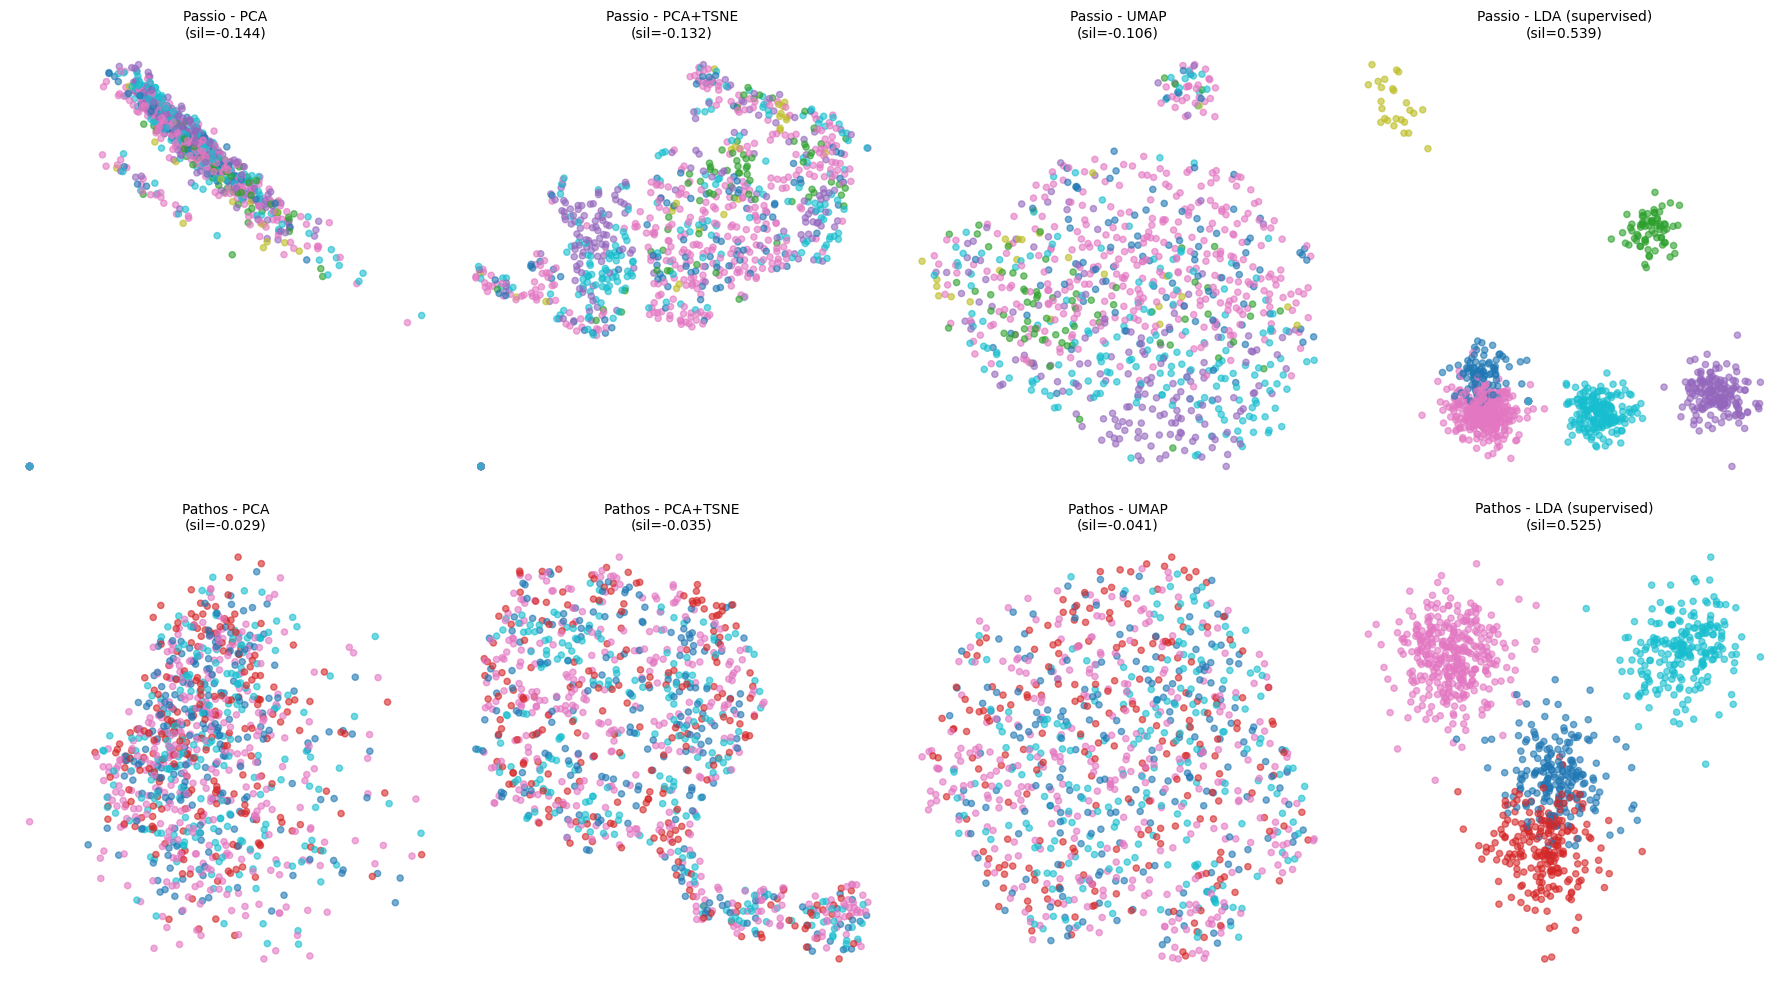


Key observation: LDA achieves clear separation while unsupervised methods show overlapping clusters.

=== Top 5 Discriminative Dimensions ===

PASSIO:
  Dim 723: 188.497
  Dim 182: 46.123
  Dim 285: 18.100
  Dim 355: 18.100
  Dim 409: 18.062

PATHOS:
  Dim 723: 23.416
  Dim 664: 9.788
  Dim 531: 8.418
  Dim  21: 8.058
  Dim 339: 7.957


In [10]:
# =============================================================================
# VISUALIZATION: Side-by-side comparison for Passio AND Pathos
# =============================================================================
fig, axes = plt.subplots(2, 4, figsize=(18, 10))

cmap = 'tab10'

# PASSIO ROW
axes[0, 0].scatter(X_pca_passio[:, 0], X_pca_passio[:, 1], c=y_passio, cmap=cmap, s=20, alpha=0.6)
axes[0, 0].set_title(f'Passio - PCA\n(sil={results_passio["PCA"]:.3f})', fontsize=10)
axes[0, 0].axis('off')

axes[0, 1].scatter(X_pca10tsne_passio[:, 0], X_pca10tsne_passio[:, 1], c=y_passio, cmap=cmap, s=20, alpha=0.6)
axes[0, 1].set_title(f'Passio - PCA+TSNE\n(sil={results_passio["PCA+TSNE(10)"]:.3f})', fontsize=10)
axes[0, 1].axis('off')

axes[0, 2].scatter(X_umap_passio[:, 0], X_umap_passio[:, 1], c=y_passio, cmap=cmap, s=20, alpha=0.6)
axes[0, 2].set_title(f'Passio - UMAP\n(sil={results_passio["UMAP(50,0.5)"]:.3f})', fontsize=10)
axes[0, 2].axis('off')

axes[0, 3].scatter(X_lda_passio[:, 0], X_lda_passio[:, 1], c=y_passio, cmap=cmap, s=20, alpha=0.6)
axes[0, 3].set_title(f'Passio - LDA (supervised)\n(sil={results_passio["LDA (supervised)"]:.3f})', fontsize=10)
axes[0, 3].axis('off')

# PATHOS ROW
axes[1, 0].scatter(X_pca_pathos[:, 0], X_pca_pathos[:, 1], c=y_pathos, cmap=cmap, s=20, alpha=0.6)
axes[1, 0].set_title(f'Pathos - PCA\n(sil={results_pathos["PCA"]:.3f})', fontsize=10)
axes[1, 0].axis('off')

axes[1, 1].scatter(X_pca10tsne_pathos[:, 0], X_pca10tsne_pathos[:, 1], c=y_pathos, cmap=cmap, s=20, alpha=0.6)
axes[1, 1].set_title(f'Pathos - PCA+TSNE\n(sil={results_pathos["PCA+TSNE(10)"]:.3f})', fontsize=10)
axes[1, 1].axis('off')

axes[1, 2].scatter(X_umap_pathos[:, 0], X_umap_pathos[:, 1], c=y_pathos, cmap=cmap, s=20, alpha=0.6)
axes[1, 2].set_title(f'Pathos - UMAP\n(sil={results_pathos["UMAP(50,0.5)"]:.3f})', fontsize=10)
axes[1, 2].axis('off')

axes[1, 3].scatter(X_lda_pathos[:, 0], X_lda_pathos[:, 1], c=y_pathos, cmap=cmap, s=20, alpha=0.6)
axes[1, 3].set_title(f'Pathos - LDA (supervised)\n(sil={results_pathos["LDA (supervised)"]:.3f})', fontsize=10)
axes[1, 3].axis('off')

plt.tight_layout()
plt.show()

print('\nKey observation: LDA achieves clear separation while unsupervised methods show overlapping clusters.')

# Feature importance
print('\n=== Top 5 Discriminative Dimensions ===')
print('\nPASSIO:')
top_dims_passio = lda_passio.get_top_dimensions(k=5)
importances_passio = lda_passio.get_feature_importances()
for idx in top_dims_passio:
    print(f'  Dim {idx:3d}: {importances_passio[idx]:.3f}')

print('\nPATHOS:')
top_dims_pathos = lda_pathos.get_top_dimensions(k=5)
importances_pathos = lda_pathos.get_feature_importances()
for idx in top_dims_pathos:
    print(f'  Dim {idx:3d}: {importances_pathos[idx]:.3f}')

In [11]:
passio_df.head(10)

,target_phrase,target_from,matched_by,target_lemmata,target_token_ids,target_kwic_idx,target_sent_idx,grela_id,target_sentence_id,start_sentence_id,...,title,not_before,not_after,emb_labert_wsd_l7,emb_labert_wsd_l11,emb_philberta_l7,emb_philberta_l11,passage,class_qwen3.8:27b,random_date
0,[passionem],canonical,lemma,[passio],[13586294],[10],[23],cc_11619,cc_11619_3010,cc_11619_3010,...,Rationale divinorum officiorum,1182.0,1190.0,"[-0.29682878, -0.20323586, 0.019369707, 0.2122...","[-0.18319201, 0.45042267, -0.53540975, 0.86238...","[0.051772878, -0.5222783, -0.20504072, 0.06473...","[-0.047733735, -0.3307349, -0.072548226, 0.057...","Raw passage: ponitur pallium , quod quae prius...",3,1184.0
1,[passionibus],canonical,lemma,[passio],[116188733],[10],[15],cc_11625,cc_11625_4659,cc_11625_4659,...,Sermones,1115.0,1183.0,"[0.1830375, 0.15600137, 0.39755675, 0.4975659,...","[-0.038745, 1.9970257, 0.39424303, 0.7459607, ...","[-0.6111965, -0.80205786, -0.0044287853, 0.070...","[-0.08531796, -0.2553357, 0.33378154, -0.11654...",Raw passage: dum morte absorpta gloriam immort...,3,1160.0
2,[passiones],canonical,lemma,[passio],[152177418],[10],[2],cc_8863,cc_8863_3096,cc_8863_3095,...,Expositio in Matthaeum,880.0,880.0,"[-0.4905524, 0.60180014, -0.23860717, -0.03198...","[-0.7095427, 1.8743895, 1.1023982, -0.07376211...","[-0.023312025, -0.6609415, -0.69900256, 0.1672...","[0.019732744, -0.37890822, -0.64410555, 0.2673...","Raw passage: nobis , ira , cupiditas , ratio ;...",5,880.0
3,[passionis],canonical,lemma,[passio],[249015546],[10],[5],cc_12133,cc_12133_2108,cc_12133_2107,...,Adversus Catharos et Valdenses c.1240,1240.0,1240.0,"[-1.2588618, 0.48098275, -0.4274315, 0.3084373...","[-1.3634653, -0.0702929, 0.042832974, -0.06806...","[0.22426616, -0.6484396, -0.14635244, -0.24269...","[0.145426, -0.47715712, 0.039284274, 0.3201577...",Raw passage: super vestem meam miserunt fortem...,3,1240.0
7,[passionem],canonical,lemma,[passio],[209249805],[10],[6],cc_12023,cc_12023_77987,cc_12023_77985,...,Quaestiones disputatae de veritate,1225.0,1274.0,"[-0.36043903, 0.16022284, 0.7772933, 0.1729873...","[-0.13217847, 0.51689017, 0.9451349, -0.861310...","[0.10208243, -0.14420539, -0.50288653, 0.00726...","[0.2673755, 0.0005200878, -0.24894485, 0.24370...",Raw passage: in quantum viator co Respondeo Di...,3,1229.0
8,[passio],canonical,lemma,[passio],[226309302],[10],[5],cc_12033,cc_12033_325969,cc_12033_325967,...,Summa Theologiae,1225.0,1274.0,"[-1.1049409, 0.65185463, 0.038487844, 0.484989...","[-0.74304426, 0.9245046, -0.6092874, -0.051851...","[-0.13562343, 0.13061413, 0.10795776, -0.28017...","[-0.048063014, 0.05332575, 0.26479942, -0.1628...",Raw passage: eius homini applicando ad 2 Ad se...,3,1235.0
9,[passionis],canonical,lemma,[passio],[90803877],[10],[11],cc_8937,cc_8937_405,cc_8937_405,...,Epistolae,780.0,856.0,"[0.29284978, 0.19549571, 0.008505528, -0.14775...","[-0.71827805, 0.41530767, -0.46403435, -0.0639...","[-0.46296462, 0.6542628, 0.009089937, -0.20633...","[-0.08461888, 1.0090022, -0.13838713, -0.13811...",Raw passage: demonstratus est antiquis sanctis...,3,794.0
10,[passionem],canonical,lemma,[passio],[178389522],[10],[15],cc_10877,cc_10877_12346,cc_10877_12346,...,Commentaria in duodecim prophetas minores,1070.0,1129.0,"[-0.17855011, 0.030730385, 0.54468894, 0.20724...","[-0.09852934, 0.8691764, 1.1270523, -0.0882746...","[0.3703245, -0.7296206, 0.034572825, -0.281344...","[0.51996666, -0.5169207, -0.030800125, -0.3992...",Raw passage: quod est Filius Domini justitiae ...,3,1094.0
11,[passio],canonical,lemma,[passio],[239571466],[10],[22],cc_12026,cc_12026_309945,cc_12026_309945,...,Scriptum super Sententiis,1225.0,1274.0,"[-0.13122545, -0.7992037, -0.24907854, 0.06800...","[-0.2679424, 0.60167336, -0.38307524, -0.70768...","[-0.31639963, -0.30197382, -0.16608498, -0.075...","[0.070428565, -0.027661253, -0.016683452, 0.19...",Raw passage: est passio dolor autem qui est ac...,5,1229.0
12,[passio],canonical,lemma,[passio],[3

In [12]:
#X_passio = np.stack(passio_df["emb_labert_wsd_l11"])
#results_passio, lda_passio, X_lda_passio, X_pca_passio, X_pca10tsne_passio, X_umap_passio = compare_all_methods(X_passio, y_passio, 'PASSIO')

In [13]:
from projections_helpers import (
         compute_century_trajectories_data,
         plot_3d_century_trajectories,
         create_label_palette
     )

In [14]:
# Prepare label names for plotting - use actual sense names from LABEL_MAP

from llmprompt_passio import LABEL_MAP as LABEL_MAP_PASSIO
from llmprompt_pathos import LABEL_MAP as LABEL_MAP_PATHOS



label_names_passio = LABEL_MAP_PASSIO
label_names_pathos = LABEL_MAP_PATHOS

# Create color palettes - must match number of unique labels in data
palette_passio = create_label_palette(len(np.unique(y_passio)))
palette_pathos = create_label_palette(len(np.unique(y_pathos)))

In [15]:
from importlib import reload
import projections_helpers
reload(projections_helpers)
from projections_helpers import (
         compute_century_trajectories_data,
         plot_3d_century_trajectories,
         create_label_palette,
        plot_3d_lda_temporal
     )   #%%



In [16]:
trajectories_passio = compute_century_trajectories_data(
         df=passio_df,
         X=X_passio,
         y=y_passio,
         lda_model=lda_passio,
         date_column='random_date',
         min_samples=5
     )     #%%

In [17]:
trajectories_pathos = compute_century_trajectories_data(
         df=pathos_df,
         X=X_pathos,
         y=y_pathos,
         lda_model=lda_pathos,
         date_column='random_date',
         min_samples=5
     )     #%%

In [18]:
trajectories_pathos

{0: {'centuries': [-550,
   -450,
   -350,
   -250,
   -150,
   -50,
   50,
   150,
   250,
   350,
   450,
   550,
   650,
   750,
   850,
   950,
   1050,
   1150],
  'x': [0.5868284702301025,
   1.3559072017669678,
   -0.02489069104194641,
   0.29051002860069275,
   1.2579638957977295,
   0.5980587601661682,
   0.30370283126831055,
   0.18581163883209229,
   0.28672847151756287,
   0.8259956240653992,
   0.40383264422416687,
   0.7013904452323914,
   1.1987073421478271,
   1.3245487213134766,
   0.6126260161399841,
   0.1529054045677185,
   0.6017477512359619,
   -0.03843678906559944],
  'y': [-2.2755305767059326,
   -2.2350032329559326,
   -1.529417872428894,
   -1.8699973821640015,
   -1.8488101959228516,
   -1.4652824401855469,
   -1.366422176361084,
   -1.8102964162826538,
   -1.7614258527755737,
   -1.6692737340927124,
   -1.2887170314788818,
   -1.980457067489624,
   -2.6138081550598145,
   -2.9097702503204346,
   -1.486184000968933,
   -2.049830913543701,
   -1.49466753005981

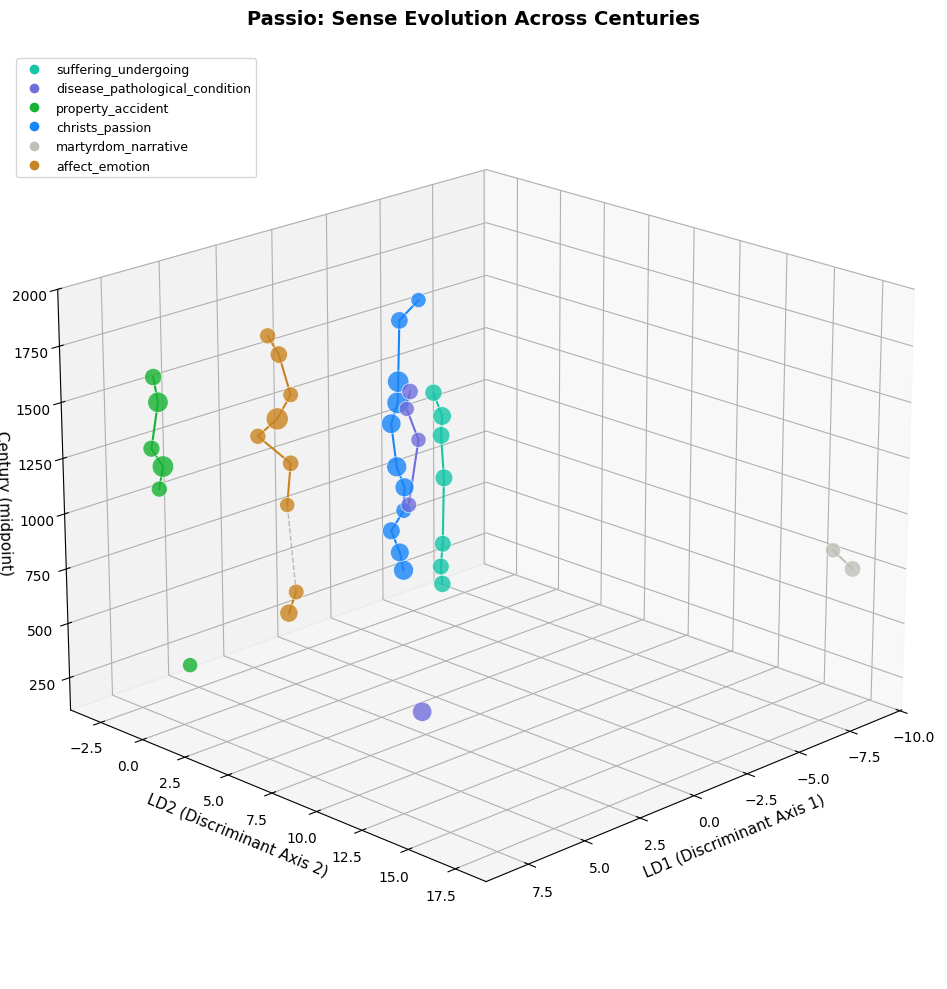

In [19]:
# Create palette and plot
palette_passio = create_label_palette(len(LABEL_MAP_PASSIO))
fig_passio = plot_3d_century_trajectories(
         trajectory_data=trajectories_passio,
         label_names=LABEL_MAP_PASSIO,
         palette=palette_passio,
         title="Passio: Sense Evolution Across Centuries",
         figsize=(14, 10),
         interpolate_gaps=True,
         max_gap_centuries=2
     )
plt.show()

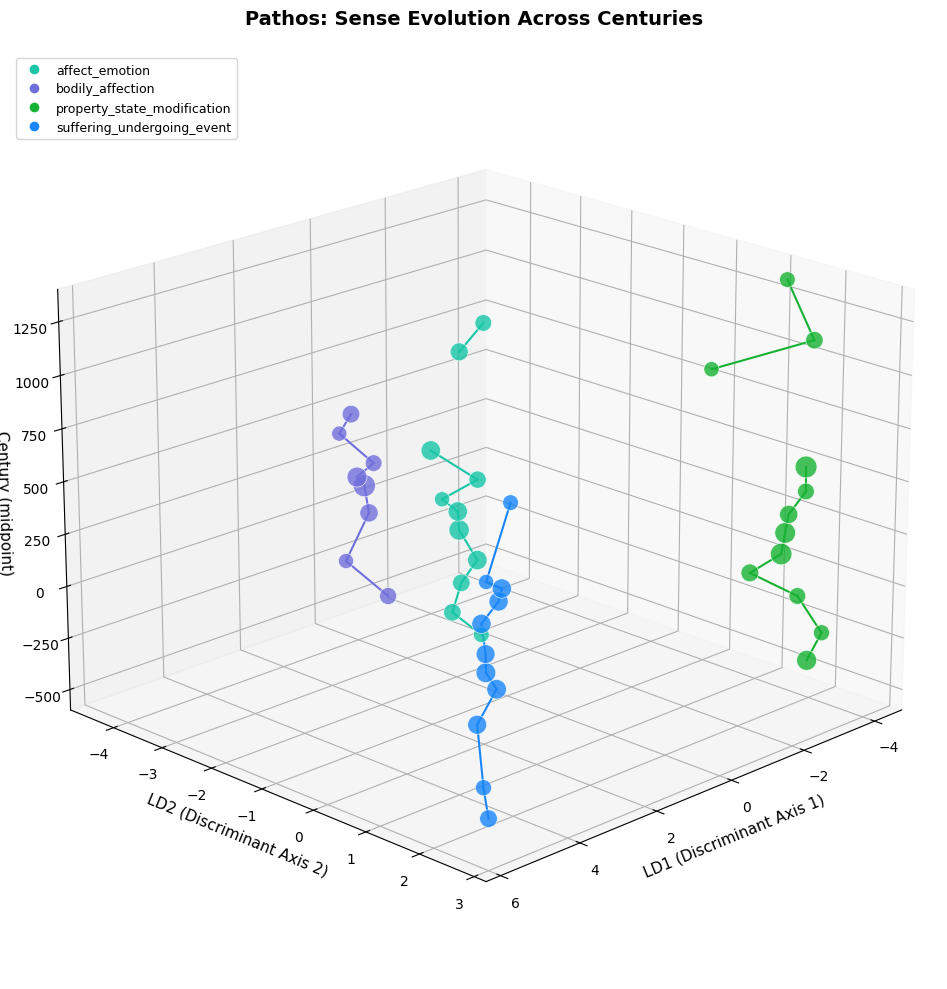

In [20]:
palette_pathos = create_label_palette(len(LABEL_MAP_PATHOS))
fig_pathos = plot_3d_century_trajectories(
         trajectory_data=trajectories_pathos,
         label_names=LABEL_MAP_PATHOS,
         palette=palette_pathos,
         title="Pathos: Sense Evolution Across Centuries",
         figsize=(14, 10),
         interpolate_gaps=True,
         max_gap_centuries=2
     )
plt.show()

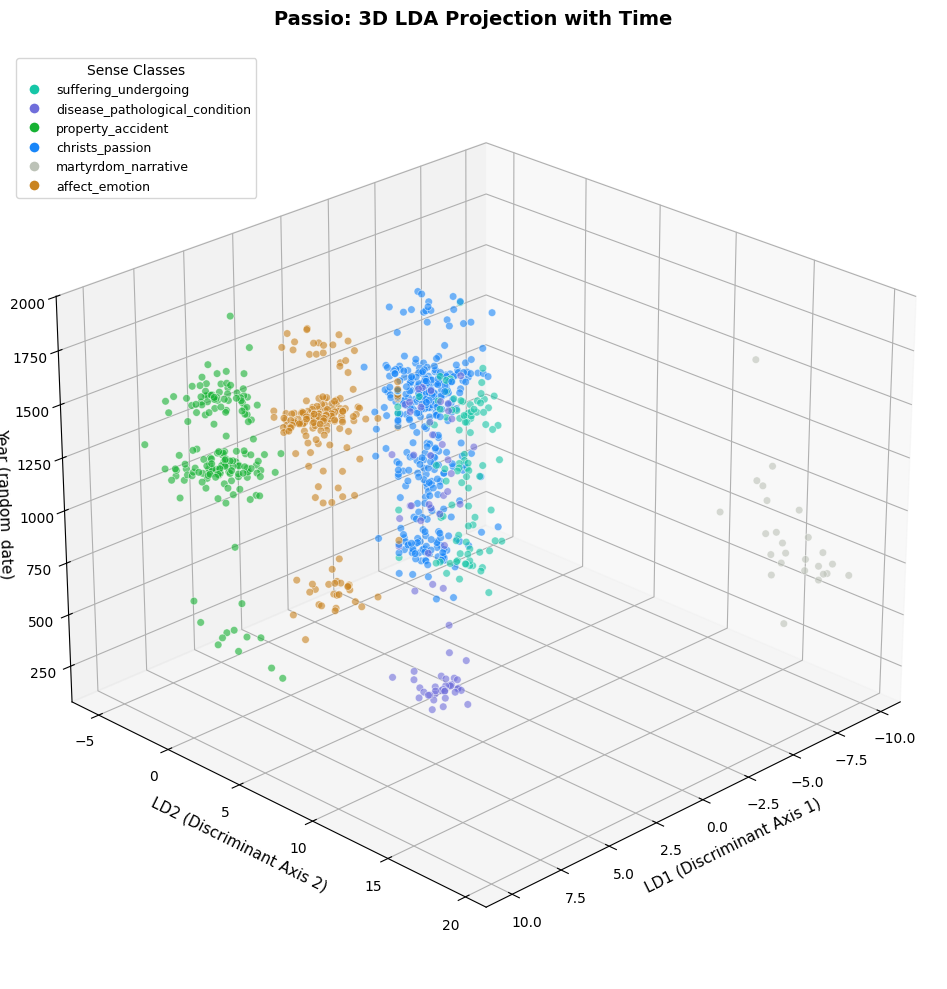

In [21]:
# For Passio
fig_passio, ax_passio = plot_3d_lda_temporal(
    X_lda=X_lda_passio,           # 2D LDA projection (shape: n_samples x 2)
    dates=passio_df["random_date"].values[:len(X_lda_passio)],  # Aligned dates
    labels=y_passio,              # Sense labels (must match X_lda length)
    label_names=LABEL_MAP_PASSIO, # Now uses actual sense names ﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿
    palette=palette_passio,       # Color palette from create_label_palette()
    title="Passio: 3D LDA Projection with Time",
    figsize=(14, 10)
)

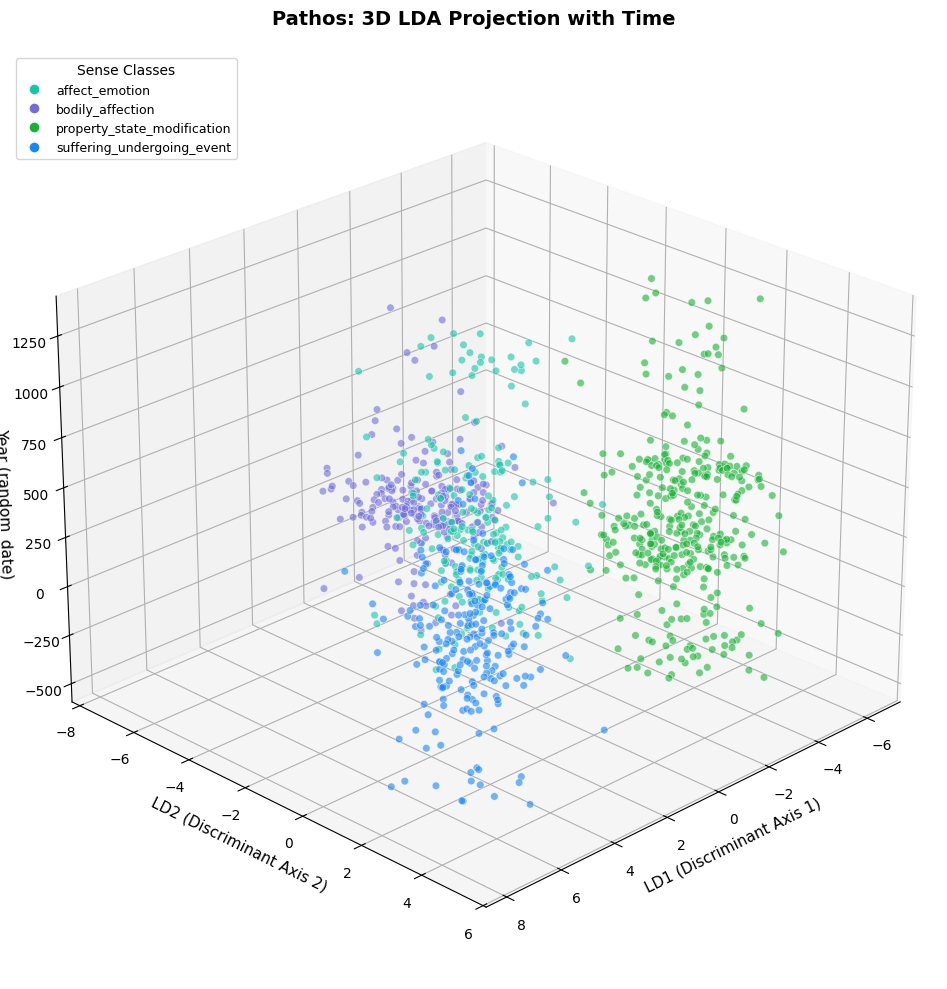

In [22]:
# For Passio
fig_pathos, ax_pathos = plot_3d_lda_temporal(
    X_lda=X_lda_pathos,           # 2D LDA projection (shape: n_samples x 2)
    dates=pathos_df["random_date"].values[:len(X_lda_pathos)],  # Aligned dates
    labels=y_pathos,              # Sense labels (must match X_lda length)
    label_names=LABEL_MAP_PATHOS, # Now uses actual sense names ﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿
    palette=palette_pathos,       # Color palette from create_label_palette()
    title="Pathos: 3D LDA Projection with Time",
    figsize=(14, 10)
)

## Combined figure: Passio projections (A, B, C) — all 3D with time

One shared figure with three horizontally adjacent 3D panels (**3:1** width:height), all showing **Passio**
with **time on the Z axis**:

- **A** — PCA + t-SNE (unsupervised) + time
- **B** — LDA projection (supervised) + time
- **C** — LDA-based century trajectories (same LDA basis as B, time on Z)

Color and legend are shared across all three panels. Tweak `ELEV` / `AZIM` to rotate all panels.

In [2]:
import matplotlib.pyplot as plt

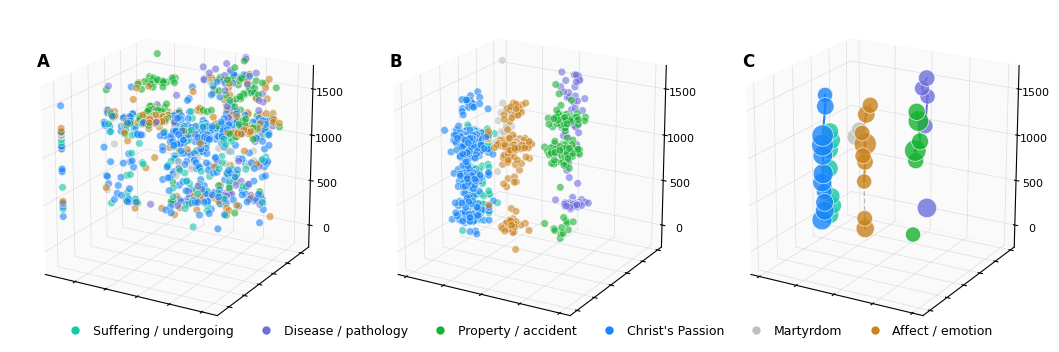

In [75]:
# =============================================================================
# CaMeMo / PhyloSen — Passio pilot visualization for ERC B1
#
# A) Contextual usages       — PCA + t-SNE + time
# B) Sense discrimination    — supervised LDA + time
# C) Diachronic trajectories — century centroids in LDA space
# =============================================================================

from importlib import reload
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D

import projections_helpers
reload(projections_helpers)

from projections_helpers import (
    plot_3d_lda_temporal,
    plot_3d_century_trajectories,
)

# ---------------------------------------------------------------------------
# Settings
# ---------------------------------------------------------------------------

ELEV, AZIM = 20, -60

dates_passio = passio_df["random_date"].values[:len(y_passio)]

LABEL_MAP_FIG = {
    0: "Suffering / undergoing",
    1: "Disease / pathology",
    2: "Property / accident",
    3: "Christ's Passion",
    4: "Martyrdom",
    5: "Affect / emotion",
}

# Wider spacing to prevent overlapping 3D axes
fig = plt.figure(figsize=(12, 4.4))


# ---------------------------------------------------------------------------
# A — Contextual usages
# ---------------------------------------------------------------------------

ax_a = fig.add_subplot(1, 3, 1, projection="3d")

plot_3d_lda_temporal(
    X_lda=X_pca10tsne_passio,
    dates=dates_passio,
    labels=y_passio,
    label_names=LABEL_MAP_FIG,
    palette=palette_passio,
    title="A", #  Contextual usages",
    ax=ax_a,
    show_legend=False,
    elev=ELEV,
    azim=AZIM,
    xlabel="",
    ylabel="",
)


# ---------------------------------------------------------------------------
# B — Sense discrimination
# ---------------------------------------------------------------------------

ax_b = fig.add_subplot(1, 3, 2, projection="3d")

plot_3d_lda_temporal(
    X_lda=X_lda_passio,
    dates=dates_passio,
    labels=y_passio,
    label_names=LABEL_MAP_FIG,
    palette=palette_passio,
    title="B", #  Sense discrimination",
    ax=ax_b,
    show_legend=False,
    elev=ELEV,
    azim=AZIM,
    xlabel="",
    ylabel="",
)


# ---------------------------------------------------------------------------
# C — Diachronic trajectories
# ---------------------------------------------------------------------------

ax_c = fig.add_subplot(1, 3, 3, projection="3d")

plot_3d_century_trajectories(
    trajectory_data=trajectories_passio,
    label_names=LABEL_MAP_FIG,
    palette=palette_passio,
    ax=ax_c,
    show_legend=False,
    elev=ELEV,
    azim=AZIM,
    title="C", #  Diachronic trajectories",
)


# ---------------------------------------------------------------------------
# Shared LDA coordinates for B and C
# ---------------------------------------------------------------------------

# B and C use the same discriminant space.
# Preserve the full extent of both panels before synchronizing limits.

xlim_b = ax_b.get_xlim()
ylim_b = ax_b.get_ylim()

xlim_c = ax_c.get_xlim()
ylim_c = ax_c.get_ylim()

shared_xlim = (
    min(xlim_b[0], xlim_c[0]),
    max(xlim_b[1], xlim_c[1]),
)

shared_ylim = (
    min(ylim_b[0], ylim_c[0]),
    max(ylim_b[1], ylim_c[1]),
)

for ax in (ax_b, ax_c):
    ax.set_xlim(shared_xlim)
    ax.set_ylim(shared_ylim)


# ---------------------------------------------------------------------------
# Shared formatting
# ---------------------------------------------------------------------------

for ax in (ax_a, ax_b, ax_c):

    ax.set_zlim(-250, 1750)
    ax.set_zticks([0, 500, 1000, 1500])

    # Keep grid-generating ticks, hide horizontal coordinates
    ax.set_xticklabels([])
    ax.set_yticklabels([])

    ax.set_xlabel("")
    ax.set_ylabel("")
    ax.set_zlabel("")

    ax.tick_params(axis="z", labelsize=8, pad=0)

    ax.grid(True)

    for axis in (ax.xaxis, ax.yaxis, ax.zaxis):
        axis._axinfo["grid"]["color"] = (0.75, 0.75, 0.75, 0.45)
        axis._axinfo["grid"]["linewidth"] = 0.5
        axis.set_pane_color((0.97, 0.97, 0.97, 0.50))

    ax.view_init(elev=20, azim=-60)
    ax.set_box_aspect((1, 1, 1.0))

    ax.set_title(
        ax.get_title(),
        fontsize=12,
        fontweight="bold",
        x=0.1,  # Move title leftward; default is approximately 0.5
        y=0.9,  # Move title downward; default is approximately 1.0
        pad=0,
    )


# ---------------------------------------------------------------------------
# Shared legend
# ---------------------------------------------------------------------------

handles = [
    Line2D(
        [0], [0],
        marker="o",
        linestyle="",
        markerfacecolor=palette_passio[lid],
        markeredgecolor="none",
        label=name,
        markersize=6,
    )
    for lid, name in LABEL_MAP_FIG.items()
]

fig.legend(
    handles=handles,
    loc="lower center",
    bbox_to_anchor=(0.5, 0.17),
    ncol=6,
    frameon=False,
    fontsize=9,
    title=None,
    columnspacing=1.6,
    handletextpad=0.4,
)


# ---------------------------------------------------------------------------
# Layout
# ---------------------------------------------------------------------------

fig.subplots_adjust(
    left=0.01,
    right=0.99,
    bottom=0.19,
    top=0.94,
    wspace=-0.25,  # Bring the three panels closer together
)

plt.show()